## 1 - imports and setup

In [1]:
%load_ext autoreload
%autoreload 2

import os
import sys

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import shap

sys.path.insert(0, os.path.abspath('..'))

import config
from src.selection import (
    combine_rankings,
    get_catboost_importance,
    get_chi2_scores,
    get_mutual_info_scores,
    get_shap_importance,
    remove_correlated,
    remove_low_variance,
)

## 2 - load data and models

In [2]:
X_train = pd.read_parquet(config.RESULTS_PATH / "X_train.parquet")
X_val   = pd.read_parquet(config.RESULTS_PATH / "X_val.parquet")
X_test  = pd.read_parquet(config.RESULTS_PATH / "X_test.parquet")
y_train = pd.read_parquet(config.RESULTS_PATH / "y_train.parquet").squeeze()
y_val   = pd.read_parquet(config.RESULTS_PATH / "y_val.parquet").squeeze()

cat_model   = joblib.load(config.OUTPUT_PATH / "models" / "catboost_model.pkl")
xgb_model   = joblib.load(config.OUTPUT_PATH / "models" / "xgboost_model.pkl")
lgb_booster = joblib.load(config.OUTPUT_PATH / "models" / "lightgbm_model.pkl")

print(f"X_train: {X_train.shape}")
print(f"X_val:   {X_val.shape}")
print(f"X_test:  {X_test.shape}")

X_train: (413378, 431)
X_val:   (88581, 431)
X_test:  (88581, 431)


## 3 - step 1: variance threshold

In [3]:
print(f"before: {X_train.shape}")
X_train_vt = remove_low_variance(X_train)
print(f"after:  {X_train_vt.shape}")

vt_cols = X_train_vt.columns.tolist()
X_val_vt = X_val[vt_cols]

before: (413378, 431)
low variance columns dropped: 49
['V1', 'V14', 'V27', 'V28', 'V41', 'V65', 'V68', 'V88', 'V89', 'V107', 'V108', 'V110', 'V111', 'V112', 'V113', 'V117', 'V118', 'V119', 'V120', 'V121', 'V122', 'V240', 'V241', 'V305', 'card1_pagerank', 'card1_pagerank_weighted', 'card1_degree', 'card1_component_size', 'card2_pagerank', 'card2_pagerank_weighted', 'card2_degree', 'card2_component_size', 'P_emaildomain_pagerank', 'P_emaildomain_pagerank_weighted', 'P_emaildomain_component_size', 'R_emaildomain_pagerank', 'R_emaildomain_pagerank_weighted', 'R_emaildomain_component_size', 'addr1_pagerank', 'addr1_pagerank_weighted', 'addr1_degree', 'addr1_component_size', 'addr2_pagerank', 'addr2_pagerank_weighted', 'addr2_degree', 'addr2_component_size', 'DeviceInfo_pagerank', 'DeviceInfo_pagerank_weighted', 'DeviceInfo_component_size']
after:  (413378, 382)


## 4 - step 2: correlation filter

before: (413378, 382)
correlated columns dropped: 96
['C2', 'C4', 'C6', 'C7', 'C8', 'C10', 'C11', 'C12', 'C14', 'D2', 'V11', 'V16', 'V18', 'V22', 'V30', 'V32', 'V33', 'V34', 'V40', 'V43', 'V49', 'V50', 'V52', 'V57', 'V58', 'V60', 'V63', 'V64', 'V70', 'V71', 'V72', 'V73', 'V74', 'V79', 'V81', 'V84', 'V85', 'V91', 'V92', 'V93', 'V94', 'V137', 'V182', 'V192', 'V193', 'V196', 'V199', 'V203', 'V206', 'V207', 'V212', 'V222', 'V225', 'V229', 'V244', 'V249', 'V251', 'V253', 'V254', 'V256', 'V266', 'V269', 'V272', 'V276', 'V278', 'V292', 'V294', 'V295', 'V298', 'V302', 'V304', 'V309', 'V311', 'V317', 'V321', 'has_identity', 'P_emaildomain__R_emaildomain__nunique', 'DeviceInfo__addr1__nunique', 'P_emaildomain__TransactionAmt__mean_log', 'R_emaildomain__card1__nunique_log', 'R_emaildomain__TransactionAmt__mean_log', 'addr1__P_emaildomain__nunique_log', 'addr1__R_emaildomain__nunique_log', 'DeviceInfo__card1__nunique_log', 'DeviceInfo__P_emaildomain__nunique_log', 'ProductCD_encoded', 'M8_encoded'

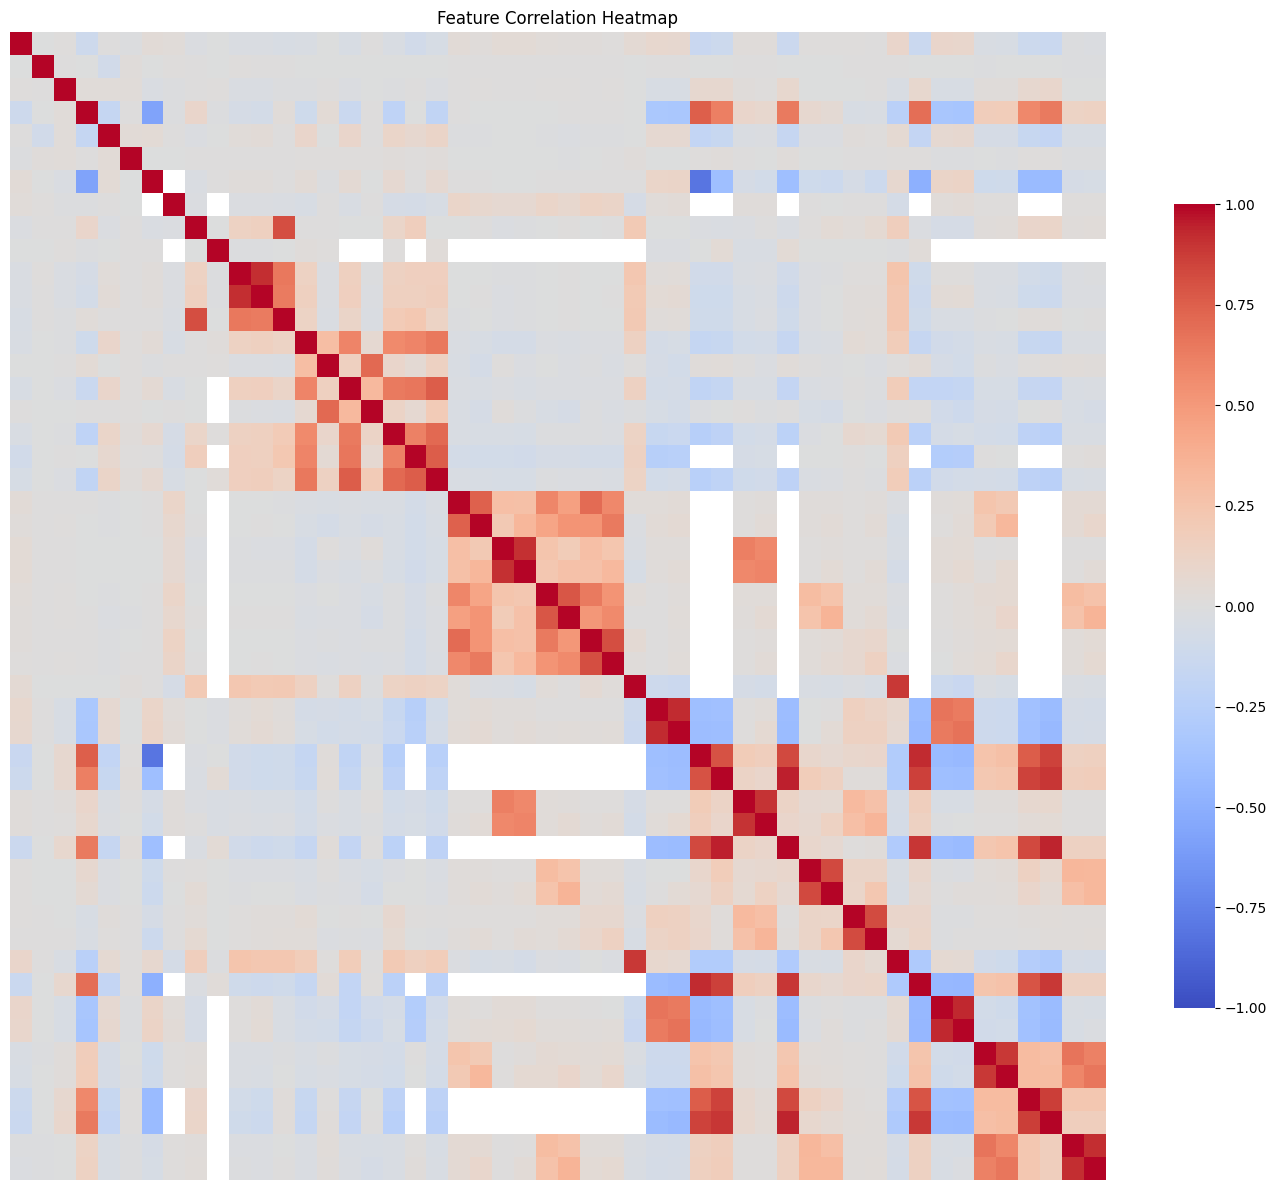

In [4]:
print(f"before: {X_train_vt.shape}")
X_train_corr = remove_correlated(X_train_vt)
print(f"after:  {X_train_corr.shape}")

corr_cols = X_train_corr.columns.tolist()
X_val_corr = X_val_vt[corr_cols]

# heatmap - sample 50 features if more remain
plot_cols = corr_cols[:50] if len(corr_cols) > 50 else corr_cols
corr_matrix = X_train_corr[plot_cols].corr()

fig, ax = plt.subplots(figsize=(14, 12))
sns.heatmap(
    corr_matrix,
    ax=ax,
    cmap="coolwarm",
    center=0,
    vmin=-1, vmax=1,
    xticklabels=False,
    yticklabels=False,
    cbar_kws={"shrink": 0.7},
)
ax.set_title("Feature Correlation Heatmap")
fig.tight_layout()
config.PLOTS_PATH.mkdir(parents=True, exist_ok=True)
fig.savefig(config.PLOTS_PATH / "correlation_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close()

## 5 - step 3: mutual information

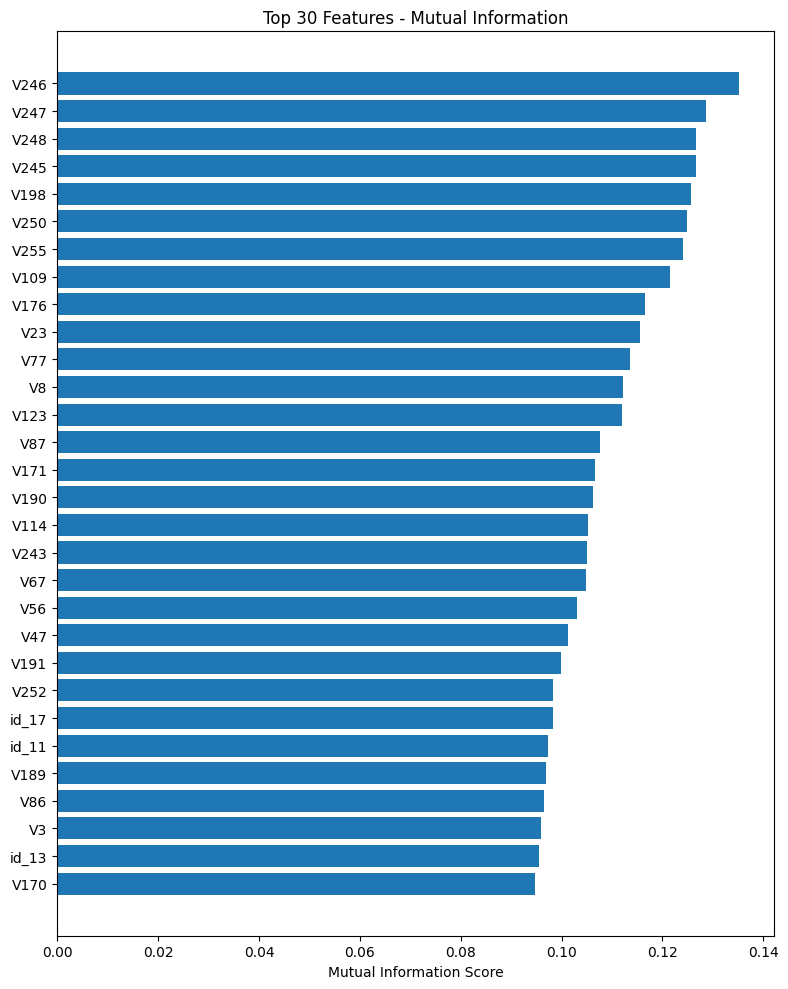

In [5]:
mi_scores = get_mutual_info_scores(X_train_corr, y_train)
top_mi = mi_scores.head(30)

fig, ax = plt.subplots(figsize=(8, 10))
ax.barh(top_mi.index[::-1], top_mi.values[::-1])
ax.set_xlabel("Mutual Information Score")
ax.set_title("Top 30 Features - Mutual Information")
fig.tight_layout()
fig.savefig(config.PLOTS_PATH / "mutual_information.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close()

## 6 - step 4: chi-squared

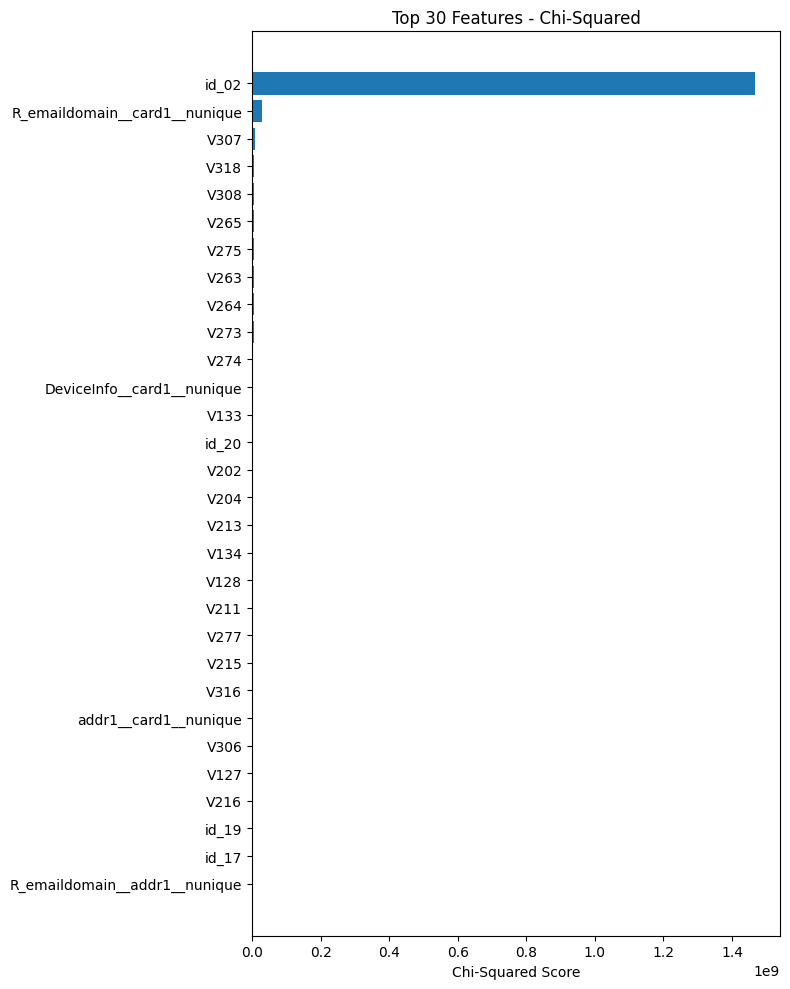

In [6]:
chi2_scores = get_chi2_scores(X_train_corr, y_train)
top_chi2 = chi2_scores.head(30)

fig, ax = plt.subplots(figsize=(8, 10))
ax.barh(top_chi2.index[::-1], top_chi2.values[::-1])
ax.set_xlabel("Chi-Squared Score")
ax.set_title("Top 30 Features - Chi-Squared")
fig.tight_layout()
fig.savefig(config.PLOTS_PATH / "chi2_scores.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close()

## 7 - step 5: catboost importance

In [12]:
from catboost import CatBoostClassifier

# retrain lightweight catboost on filtered feature set for importance
cat_cols_filtered = []

cat_model_filtered = CatBoostClassifier(
    iterations=300,
    learning_rate=0.05,
    depth=6,
    eval_metric='AUC',
    random_seed=config.RANDOM_STATE,
    verbose=100
)

cat_model_filtered.fit(
    X_train_corr, y_train,
    eval_set=(X_val_corr, y_val),
    cat_features=cat_cols_filtered
)

0:	test: 0.6714653	best: 0.6714653 (0)	total: 69.9ms	remaining: 20.9s
100:	test: 0.8651723	best: 0.8651723 (100)	total: 7.45s	remaining: 14.7s
200:	test: 0.8751233	best: 0.8751233 (200)	total: 15.2s	remaining: 7.46s
299:	test: 0.8799297	best: 0.8799297 (299)	total: 22.8s	remaining: 0us

bestTest = 0.8799297223
bestIteration = 299



CatBoostClassifier(depth=6, eval_metric='AUC', iterations=300, learning_rate=0.05, random_seed=42, verbose=100)

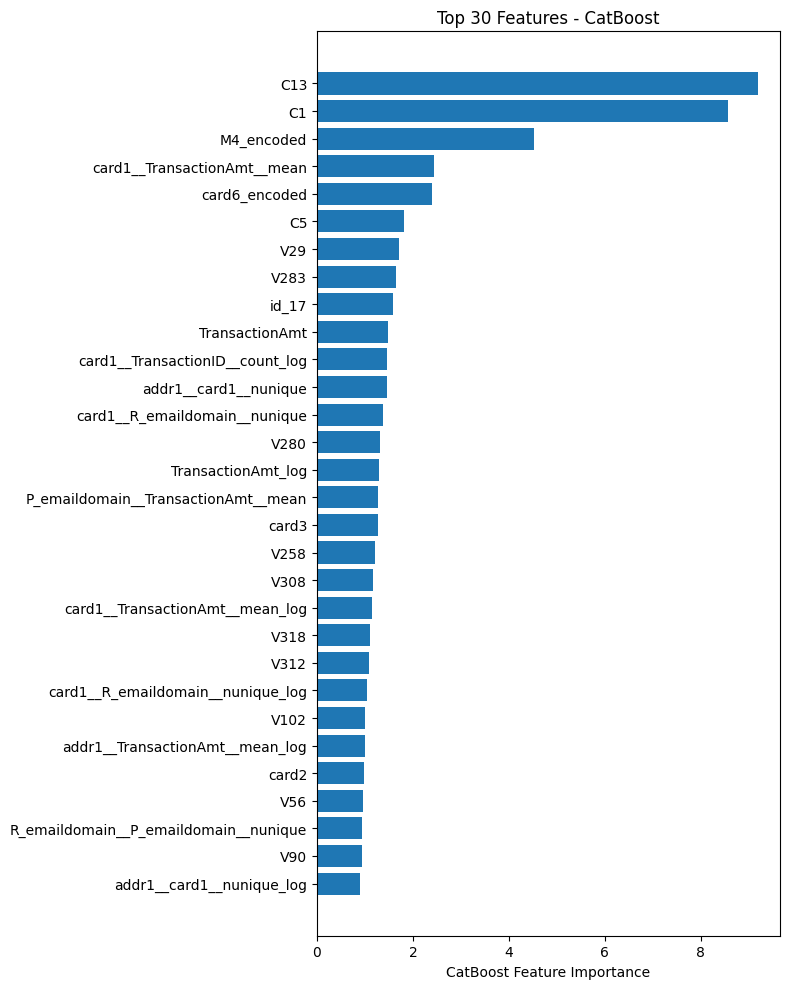

In [13]:
cat_imp = get_catboost_importance(cat_model_filtered, X_train_corr)
top_cat = cat_imp.head(30)

fig, ax = plt.subplots(figsize=(8, 10))
ax.barh(top_cat.index[::-1], top_cat.values[::-1])
ax.set_xlabel("CatBoost Feature Importance")
ax.set_title("Top 30 Features - CatBoost")
fig.tight_layout()
fig.savefig(config.PLOTS_PATH / "catboost_importance.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close()

## 8 - step 6: shap values

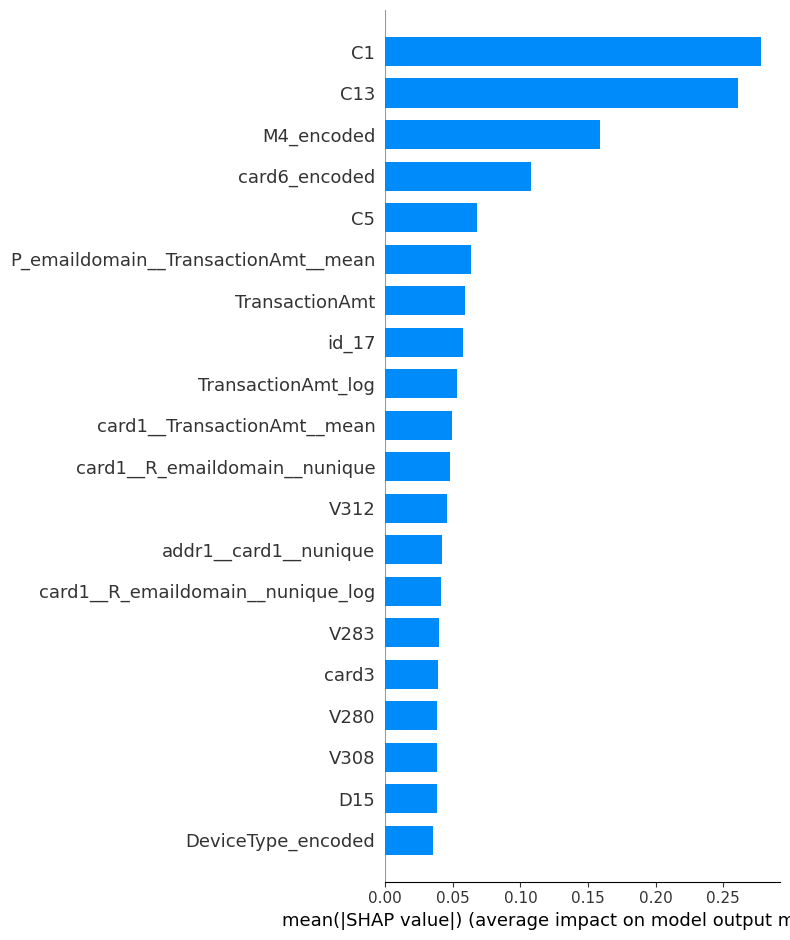

In [14]:
shap_imp = get_shap_importance(cat_model_filtered, X_train_corr)

# summary plot - shap built-in matplotlib mode
sample = X_train_corr.sample(n=min(5000, len(X_train_corr)), random_state=42)
explainer = shap.TreeExplainer(cat_model_filtered)
shap_vals = explainer.shap_values(sample)
if isinstance(shap_vals, list):
    shap_vals = shap_vals[1]

shap.summary_plot(shap_vals, sample, plot_type="bar", show=False)
plt.savefig(config.PLOTS_PATH / "shap_summary.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close()

## 9 - combine rankings and select features

In [15]:
rank_dicts = {
    "mutual_info": mi_scores,
    "chi2":        chi2_scores,
    "catboost":    cat_imp,
    "shap":        shap_imp,
}

ranking_df = combine_rankings(rank_dicts, top_n=100)
display(ranking_df)

,feature,mutual_info_rank,chi2_rank,catboost_rank,shap_rank,mean_rank
0,id_17,24.0,29.0,9.0,8.0,17.50
1,R_emaildomain__TransactionAmt__mean,49.0,48.0,43.0,40.0,45.00
2,R_emaildomain__P_emaildomain__nunique,97.0,50.0,28.0,24.0,49.75
3,addr1__card1__nunique,151.0,24.0,12.0,13.0,50.00
4,id_20,87.0,14.0,54.0,46.0,50.25
...,...,...,...,...,...,...
281,V104,278.0,222.0,220.0,218.0,234.50
282,V297,281.0,233.0,221.0,221.0,239.00
283,V172,283.0,252.0,221.0,221.0,244.25
284,C3,284.0,253.0,221.0,221.0,244.75


In [16]:
# features in top 100 of at least 2 methods
rank_cols = ["mutual_info_rank", "chi2_rank", "catboost_rank", "shap_rank"]
ranking_df["n_top100"] = (ranking_df[rank_cols] <= 100).sum(axis=1)
selected_features = ranking_df[ranking_df["n_top100"] >= 2]["feature"].tolist()

print(f"selected features: {len(selected_features)}")
print(selected_features)

config.RESULTS_PATH.mkdir(parents=True, exist_ok=True)
with open(config.RESULTS_PATH / "selected_features.txt", "w") as f:
    f.write("\n".join(selected_features))

selected features: 115
['id_17', 'R_emaildomain__TransactionAmt__mean', 'R_emaildomain__P_emaildomain__nunique', 'addr1__card1__nunique', 'id_20', 'V258', 'V189', 'C1', 'DeviceInfo__card1__nunique', 'V308', 'card1', 'V246', 'V318', 'card3', 'card1__TransactionID__count', 'TransactionAmt', 'V312', 'V283', 'C5', 'card6_encoded', 'R_emaildomain__card1__nunique', 'R_emaildomain__addr1__nunique_log', 'card1__TransactionAmt__mean', 'DeviceInfo__P_emaildomain__nunique', 'C13', 'V45', 'V247', 'card1__TransactionAmt__std', 'M4_encoded', 'V315', 'V29', 'V307', 'D10', 'V134', 'R_emaildomain__P_emaildomain__nunique_log', 'V261', 'V257', 'DeviceInfo_encoded', 'P_emaildomain__TransactionAmt__mean', 'V90', 'addr1', 'D1', 'V62', 'addr1__card1__nunique_log', 'V128', 'V282', 'id_13', 'card1__R_emaildomain__nunique', 'V56', 'V243', 'V313', 'V280', 'V303', 'id_19', 'V69', 'addr2', 'V67', 'M6_encoded', 'addr1__TransactionAmt__mean_log', 'V87', 'R_emaildomain_encoded', 'addr1__TransactionAmt__mean', 'V102',

## 10 - save filtered splits

In [17]:
# keep only selected features present in each split
sel_cols = [c for c in selected_features if c in X_train_corr.columns]

X_train_sel = X_train_corr[sel_cols]
X_val_sel   = X_val_corr[[c for c in sel_cols if c in X_val_corr.columns]]
X_test_sel  = X_test[[c for c in sel_cols if c in X_test.columns]]

print(f"X_train_sel: {X_train_sel.shape}")
print(f"X_val_sel:   {X_val_sel.shape}")
print(f"X_test_sel:  {X_test_sel.shape}")

X_train_sel.to_parquet(config.RESULTS_PATH / "X_train_selected.parquet")
X_val_sel.to_parquet(config.RESULTS_PATH / "X_val_selected.parquet")
X_test_sel.to_parquet(config.RESULTS_PATH / "X_test_selected.parquet")

print("saved X_train_selected, X_val_selected, X_test_selected")

X_train_sel: (413378, 115)
X_val_sel:   (88581, 115)
X_test_sel:  (88581, 115)
saved X_train_selected, X_val_selected, X_test_selected


# 11 Examine Graph Cols

graph features (28 columns) were eliminated at the variance 
threshold step — 25 dropped due to near-zero variance, 
3 remaining dropped by correlation filter. the aggregation 
features (entity__target__nunique) capture equivalent 
linkage signal in a more direct form and survived selection.
this suggests graph metrics add limited incremental value 
over well-engineered tabular aggregations on this dataset.

In [18]:
graph_cols = [c for c in selected_features if 'pagerank' in c or 'degree' in c or 'component' in c]
print(graph_cols)

[]


In [21]:
g = [c for c in ranking_df.feature if 'pagerank' in c or 'degree' in c or 'component' in c]
ranking_df[ranking_df.feature.isin(g)]

,feature,mutual_info_rank,chi2_rank,catboost_rank,shap_rank,mean_rank,n_top100


In [23]:
# check which step killed graph features
graph_cols_original = [c for c in X_train.columns if 
                       'pagerank' in c or 'degree' in c or 'component' in c]
print(f'graph features in original X_train: {len(graph_cols_original)}')
print(graph_cols_original)

graph_cols_after_variance = [c for c in X_train_vt.columns if 'pagerank' in c or 'degree' in c or 'component' in c]
print(f'\ngraph features after variance filter: {len(graph_cols_after_variance)}')

graph_cols_after_corr = [c for c in X_train_corr.columns if 
                          'pagerank' in c or 'degree' in c or 'component' in c]
print(f'\ngraph features after correlation filter: {len(graph_cols_after_corr)}')

graph features in original X_train: 28
['card1_pagerank', 'card1_pagerank_weighted', 'card1_degree', 'card1_component_size', 'card2_pagerank', 'card2_pagerank_weighted', 'card2_degree', 'card2_component_size', 'P_emaildomain_pagerank', 'P_emaildomain_pagerank_weighted', 'P_emaildomain_degree', 'P_emaildomain_component_size', 'R_emaildomain_pagerank', 'R_emaildomain_pagerank_weighted', 'R_emaildomain_degree', 'R_emaildomain_component_size', 'addr1_pagerank', 'addr1_pagerank_weighted', 'addr1_degree', 'addr1_component_size', 'addr2_pagerank', 'addr2_pagerank_weighted', 'addr2_degree', 'addr2_component_size', 'DeviceInfo_pagerank', 'DeviceInfo_pagerank_weighted', 'DeviceInfo_degree', 'DeviceInfo_component_size']

graph features after variance filter: 3

graph features after correlation filter: 0
